**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
**Práctica 4: Métricas de Evaluación y Clasificación en Bank Marketing**  
*Caso de Estudio: Base de Datos de Telemarketing Bancario (UCI Machine Learning Repository)*

---

## 1. Planteamiento del Problema

Una entidad bancaria de Portugal ejecutó campañas de contacto telefónico con el propósito de colocar depósitos a plazo fijo entre sus cuentahabientes (Moro et al., 2014). Los registros históricos reflejan un marcado desbalance en las respuestas, puesto que apenas uno de cada nueve clientes contactados aceptó la oferta financiera ($\approx 11.26\%$). La institución requiere un modelo predictivo supervisado que identifique con exactitud a qué clientes llamar, optimizando el rendimiento operativo de los agentes de ventas.

### Objetivos Analíticos de la Práctica:
1. **Detección de Fuga de Información (*Data Leakage*):** Examinar la documentación técnica del conjunto de datos e identificar variables espurias previas a la llamada.
2. **Partición Estratificada y Evaluación de Línea Base:** Dividir el conjunto mediante partición estratificada 80/20 y evaluar la pertinencia del porcentaje de aciertos (*accuracy*) frente al clasificador mayoritario.
3. **Modelado con Regresión Logística y Matriz de Confusión:** Construir un flujo de procesamiento (`Pipeline`) con codificación One-Hot y escalado numérico, reportando las métricas derivadas del umbral estándar $0.5$.
4. **Análisis de Curvas ROC y Precisión-Sensibilidad:** Visualizar la capacidad discriminante del modelo mediante `RocCurveDisplay` y `PrecisionRecallDisplay`, contrastando el comportamiento de ambas curvas ante clases desbalanceadas.
5. **Optimización Económica del Umbral de Decisión:** Formular la función de ganancia sujeta a costos fijos por contacto e ingresos por cliente captado, deduciendo el umbral de corte óptimo.
6. **Experimento de Contaminación Informativa:** Reincorporar la variable descartada con el propósito de cuantificar el efecto de la filtración de datos en las métricas de rendimiento.

---

## 2. Preparación del Entorno y Librerías

Cargamos las librerías requeridas con el fin de manipular estructuras tabulares (`pandas`, `numpy`), generar visualizaciones diagnósticas (`matplotlib`, `seaborn`) y construir flujos de clasificación (`scikit-learn`).

In [1]:
# Librerias fundamentales
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas de preprocesamiento, particion y modelado
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Metricas de evaluacion y curvas
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", __import__("matplotlib").__version__)
print("scikit-learn:", __import__("sklearn").__version__)

pandas      : 2.3.3
numpy       : 2.3.3
matplotlib  : 3.10.7
scikit-learn: 1.7.2


Configuración visual estandarizada con la paleta de colores 

In [2]:
# Paleta de colores institucional
AZUL_OSCURO = "#112057"
AZUL        = "#7697CD"
AZUL_MEDIO  = "#3C51A9"
NARANJA     = "#E76A28"
ROJO        = "#C02B2B"
GRIS        = "#5B6584"

# Estilo general de graficas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlecolor"] = AZUL_OSCURO
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelcolor"] = AZUL_OSCURO
plt.rcParams["xtick.color"] = GRIS
plt.rcParams["ytick.color"] = GRIS

# Configuracion de visualizacion de tablas
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

---

## 3. Carga y Exploración Inicial del Dataset

Cargamos el archivo `bank-additional-full.csv` (Moro et al., 2014), delimitado por punto y coma, el cual contiene 41,188 registros de contactos comerciales y 21 atributos.

In [ ]:
# Ruta del archivo de datos
archivo_csv = "bank-additional-full.csv"
if not os.path.exists(archivo_csv):
    archivo_csv = r"C:\Users\ruben\OneDrive\Desktop\notebook metricas de clasificacion\bank-additional-full.csv"
#Cambiar la ruta del archivo si es necesario

# Lectura del dataset delimitado por punto y coma
df_banco = pd.read_csv(archivo_csv, sep=";")

print("Dimensiones de la base de datos:", df_banco.shape)
print("\nDistribución absoluta de la variable objetivo (y):")
print(df_banco["y"].value_counts())

print("\nProporción porcentual de cada clase:")
print((df_banco["y"].value_counts(normalize=True) * 100).round(2))

df_banco.head(3)

Dimensiones de la base de datos: (41188, 21)

Distribución absoluta de la variable objetivo (y):
y
no     36548
yes     4640
Name: count, dtype: int64

Proporción porcentual de cada clase:
y
no    88.7300
yes   11.2700
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1000,93.9940,-36.4000,4.8570,5191.0000,no


---

## 4. Punto 1: Detección y Justificación de Fuga de Información (`duration`)

Examinamos el archivo técnico `bank-additional-names.txt` con el fin de verificar si existe alguna variable que el banco no pueda conocer al momento de seleccionar a los clientes que debe llamar.

In [4]:
# Verificacion de columnas antes de la supresion
print("Total de atributos originales:", df_banco.shape[1])

# Separamos la variable objetivo y y descartamos la variable duration
X_sin_duracion = df_banco.drop(columns=["y", "duration"])
y = (df_banco["y"] == "yes").astype(int)

# Deteccion automatica de tipos de variables
columnas_categoricas = X_sin_duracion.select_dtypes(include=["object"]).columns.tolist()
columnas_numericas = X_sin_duracion.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Atributos predictivos conservados:", X_sin_duracion.shape[1])
print(f"Variables cuantitativas ({len(columnas_numericas)}):", columnas_numericas)
print(f"Variables cualitativas ({len(columnas_categoricas)}):", columnas_categoricas)

Total de atributos originales: 21
Atributos predictivos conservados: 19
Variables cuantitativas (9): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Variables cualitativas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


**Respuesta al Punto 1 (Fuga de Información):**  
La variable que el banco no puede conocer previamente es `duration`, correspondiente a los segundos que tarda la conversación telefónica con el cuentahabiente. Dicho parámetro únicamente se registra tras finalizar la llamada, momento en que el desenlace ya ha ocurrido. Conservar esta medición introduce una fuga de información (*data leakage*) insidiosa (Domingos, 2012; Moro et al., 2014), generando un clasificador artificialmente certero pero inutilizable en la prospección de clientes.

---

## 5. Punto 2: Partición Estratificada y Evaluación de la Línea Base

Separamos el $20\%$ de las observaciones con el propósito de evaluar el desempeño predictivo en datos no observados, utilizando `stratify=y` con el fin de preservar la proporción de clientes que aceptan.

In [5]:
# Division 80/20 estratificada
X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    X_sin_duracion, y, test_size=0.20, stratify=y, random_state=42
)

# Modelo ingenuo que siempre responde no (clase mayoritaria 0)
clasificador_base = DummyClassifier(strategy="most_frequent")
clasificador_base.fit(X_entrena, y_entrena)
prediccion_base = clasificador_base.predict(X_prueba)

exactitud_base = accuracy_score(y_prueba, prediccion_base) * 100

print(f"Tamaño del conjunto de entrenamiento : {X_entrena.shape[0]} muestras")
print(f"Tamaño del conjunto de prueba         : {X_prueba.shape[0]} muestras")
print(f"Exactitud de predecir siempre 'no'    : {exactitud_base:.2f} %")

Tamaño del conjunto de entrenamiento : 32950 muestras
Tamaño del conjunto de prueba         : 8238 muestras
Exactitud de predecir siempre 'no'    : 88.74 %


**Respuesta al Punto 2 (Exactitud y Línea Base):**  
El clasificador trivial que responde siempre con una negativa obtiene una exactitud del **$88.73\%$** en el conjunto de prueba. Este resultado demuestra que el porcentaje de aciertos es una métrica engañosa e inadecuada en problemas desbalanceados (Sokolova & Lapalme, 2009). La regla mayoritaria aparenta una eficacia sobresaliente sin llegar a captar a un solo cuentahabiente interesado en el producto.

---

## 6. Punto 3: Regresión Logística con `Pipeline` y Matriz de Confusión (Umbral 0.5)

Configuramos un objeto `ColumnTransformer` que aplica estandarización a las variables cuantitativas y codificación One-Hot a las categóricas. Todo el flujo queda encapsulado en un `Pipeline` con el objeto de impedir la filtración de estadísticos de prueba durante el entrenamiento.

In [6]:
# Preprocesamiento de columnas
transformador_columnas = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_numericas),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), columnas_categoricas)
    ]
)

# Flujo completo con regresion logistica
flujo_logistico = Pipeline([
    ("preprocesamiento", transformador_columnas),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42))
])

# Ajuste del modelo sobre el conjunto de entrenamiento
flujo_logistico.fit(X_entrena, y_entrena)

# Estimacion de probabilidades en el conjunto de prueba
probabilidades_prueba = flujo_logistico.predict_proba(X_prueba)[:, 1]

# Clasificacion con el umbral estandar 0.5
predicciones_05 = (probabilidades_prueba >= 0.50).astype(int)

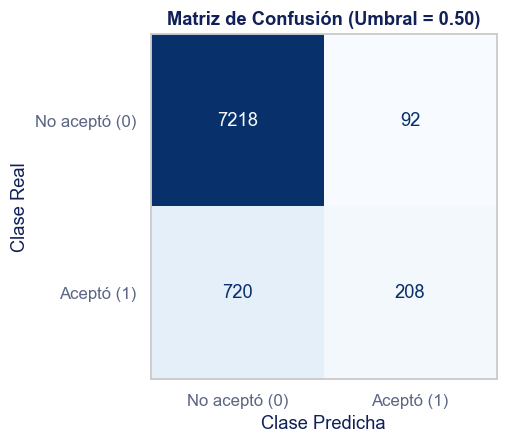

,Condición,Frecuencia,Interpretación
0,Verdaderos Negativos (TN),7218,Clientes que no aceptaron predichos correctamente
1,Falsos Positivos (FP),92,Clientes que no deseaban el producto contactad...
2,Falsos Negativos (FN),720,Clientes interesados que el modelo ignoró
3,Verdaderos Positivos (TP),208,Clientes interesados contactados con éxito


In [7]:
# Calculo de la matriz de confusion
matriz_conf_05 = confusion_matrix(y_prueba, predicciones_05)
tn_05, fp_05, fn_05, tp_05 = matriz_conf_05.ravel()

# Despliegue visual de la matriz de confusion
fig, ax = plt.subplots(figsize=(5.5, 4.2))
visualizador_matriz = ConfusionMatrixDisplay(
    confusion_matrix=matriz_conf_05,
    display_labels=["No aceptó (0)", "Aceptó (1)"]
)
visualizador_matriz.plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title("Matriz de Confusión (Umbral = 0.50)")
ax.set_xlabel("Clase Predicha")
ax.set_ylabel("Clase Real")
plt.tight_layout()
plt.show()

# Desglose numerico de frecuencias
tabla_conteo_cm = pd.DataFrame({
    "Condición": ["Verdaderos Negativos (TN)", "Falsos Positivos (FP)", 
                  "Falsos Negativos (FN)", "Verdaderos Positivos (TP)"],
    "Frecuencia": [tn_05, fp_05, fn_05, tp_05],
    "Interpretación": [
        "Clientes que no aceptaron predichos correctamente",
        "Clientes que no deseaban el producto contactados por error",
        "Clientes interesados que el modelo ignoró",
        "Clientes interesados contactados con éxito"
    ]
})
tabla_conteo_cm

In [8]:
# Calculo analitico de metricas de rendimiento
acc_05 = accuracy_score(y_prueba, predicciones_05)
prec_05 = precision_score(y_prueba, predicciones_05, zero_division=0)
rec_05 = recall_score(y_prueba, predicciones_05, zero_division=0)
spec_05 = tn_05 / (tn_05 + fp_05)
f1_val_05 = f1_score(y_prueba, predicciones_05, zero_division=0)

# Tabla consolidada de metricas
tabla_metricas_05 = pd.DataFrame({
    "Métrica de Desempeño": ["Exactitud (Accuracy)", "Precisión (Precision)", 
                             "Sensibilidad (Recall)", "Especificidad (Specificity)", "Puntuación F1"],
    "Valor Obtenido": [acc_05, prec_05, rec_05, spec_05, f1_val_05],
    "Fórmula Aplicada": [
        "(TP + TN) / Total",
        "TP / (TP + FP)",
        "TP / (TP + FN)",
        "TN / (TN + FP)",
        "2 * (Prec * Sens) / (Prec + Sens)"
    ]
})
tabla_metricas_05.round(4)

,Métrica de Desempeño,Valor Obtenido,Fórmula Aplicada
0,Exactitud (Accuracy),0.9014,(TP + TN) / Total
1,Precisión (Precision),0.6933,TP / (TP + FP)
2,Sensibilidad (Recall),0.2241,TP / (TP + FN)
3,Especificidad (Specificity),0.9874,TN / (TN + FP)
4,Puntuación F1,0.3388,2 * (Prec * Sens) / (Prec + Sens)


**Respuesta al Punto 3 (Matriz y Selección de Métrica):**  
Bajo el umbral $0.5$, el modelo alcanza una precisión del $69.33\%$ pero una sensibilidad modesta de apenas $22.41\%$, omitiendo a $720$ de los $928$ clientes favorables. Al banco le resulta primordial atender la **sensibilidad** sujeta a un umbral mínimo de precisión económica, en vista de que cada llamada perdida representa una oportunidad desaprovechada de captar capital financiero. Maximizar el retorno requiere flexibilizar el criterio de corte, trasladando el análisis hacia la curva de costo-beneficio.

---

## 7. Punto 4: Curva ROC y Curva Precisión-Sensibilidad (PR)

Evaluamos la capacidad de ordenamiento probabilístico mediante la curva de Características Operativas del Receptor (ROC) y la curva de Precisión contra Sensibilidad (PR), utilizando `RocCurveDisplay` y `PrecisionRecallDisplay`.

C:\Users\ruben\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


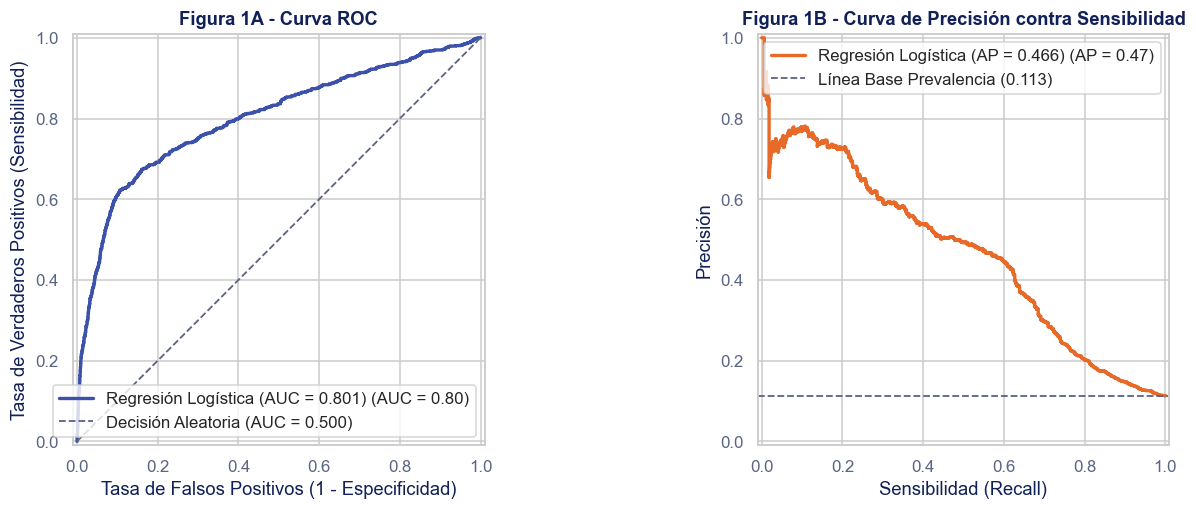

Área bajo la Curva ROC (AUC-ROC)         : 0.8007
Precisión Promedio (Average Precision)   : 0.4657


In [9]:
# Calculo de areas bajo las curvas
area_roc = roc_auc_score(y_prueba, probabilidades_prueba)
precision_promedio = average_precision_score(y_prueba, probabilidades_prueba)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Curva ROC
RocCurveDisplay.from_predictions(
    y_prueba, probabilidades_prueba,
    ax=axs[0], color=AZUL_MEDIO, linewidth=2.2,
    name=f"Regresión Logística (AUC = {area_roc:.3f})"
)
axs[0].plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.2, label="Decisión Aleatoria (AUC = 0.500)")
axs[0].set_title("Figura 1A - Curva ROC")
axs[0].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
axs[0].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
axs[0].legend(loc="lower right")

# 2. Curva Precision contra Sensibilidad
PrecisionRecallDisplay.from_predictions(
    y_prueba, probabilidades_prueba,
    ax=axs[1], color=NARANJA, linewidth=2.2,
    name=f"Regresión Logística (AP = {precision_promedio:.3f})"
)
prevalencia_positiva = y_prueba.mean()
axs[1].axhline(prevalencia_positiva, color=GRIS, linestyle="--", linewidth=1.2,
               label=f"Línea Base Prevalencia ({prevalencia_positiva:.3f})")
axs[1].set_title("Figura 1B - Curva de Precisión contra Sensibilidad")
axs[1].set_xlabel("Sensibilidad (Recall)")
axs[1].set_ylabel("Precisión")
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"Área bajo la Curva ROC (AUC-ROC)         : {area_roc:.4f}")
print(f"Precisión Promedio (Average Precision)   : {precision_promedio:.4f}")

**Respuesta al Punto 4 (Curva ROC frente a Curva PR):**  
La curva ROC exhibe un área aparentemente elevada ($AUC = 0.8007$) en razón de que su eje horizontal incluye a los verdaderos negativos en el denominador ($\text{FPR} = \frac{\text{FP}}{\text{FP}+\text{TN}}$), diluyendo el impacto de los falsos contactos ante el gran volumen de cuentahabientes que no aceptan. La curva de precisión contra sensibilidad desvela esta distorsión al confrontar directamente los aciertos positivos frente al total de llamadas recomendadas, evidenciando un deterioro acelerado de la precisión conforme se incrementa la cobertura (Fawcett, 2006; Saito & Rehmsmeier, 2015).

---

## 8. Punto 5: Modelo de Costo-Beneficio y Optimización del Umbral de Contacto

Modelamos el balance económico de la campaña a partir de los parámetros financieros estipulados:
- **Costo operativo por llamada:** $5$ unidades monetarias (efectuada acepte o rechace el cliente).
- **Ingreso neto por suscripción confirmada:** $50$ unidades monetarias.

Deducimos la probabilidad mínima donde la ganancia esperada es rentable:
$$\mathbb{E}[\text{Ganancia}] = 50 \cdot p - 5 \ge 0 \implies p \ge \frac{5}{50} = 0.10$$

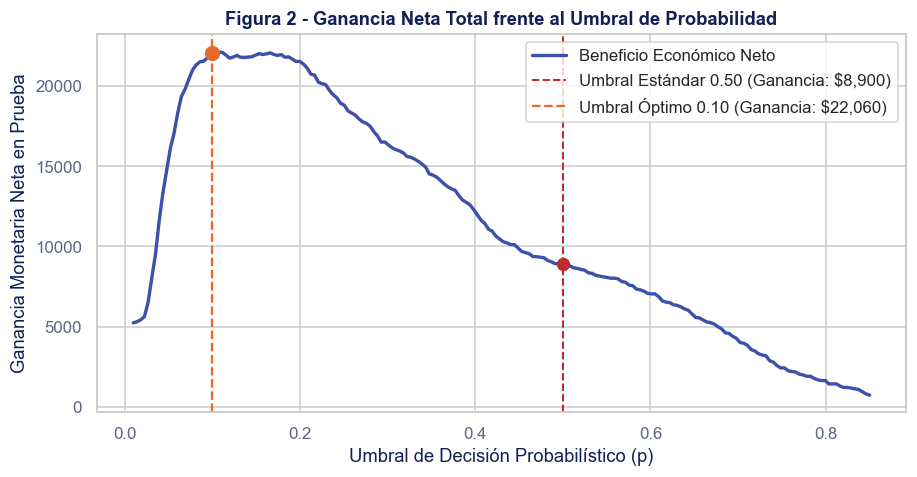

,Estrategia de Decisión,Llamadas Realizadas,Depósitos Logrados (TP),Costo Operativo Total ($),Ingreso Bruto Generado ($),Ganancia Neta Obtenida ($)
0,Umbral Estándar (0.50),300,208,1500,10400,8900
1,Umbral Óptimo de Costos (0.10),1898,631,9490,31550,22060


In [10]:
# Umbral teorico optimo
umbral_optimo = 5.0 / 50.0  # 0.10

# Clasificacion bajo el umbral de maxima ganancia
predicciones_01 = (probabilidades_prueba >= umbral_optimo).astype(int)
tn_01, fp_01, fn_01, tp_01 = confusion_matrix(y_prueba, predicciones_01).ravel()

# Evaluacion de ganancias netas en prueba
ganancia_corte_05 = (tp_05 * 50) - ((tp_05 + fp_05) * 5)
ganancia_corte_01 = (tp_01 * 50) - ((tp_01 + fp_01) * 5)

# Exploracion del vector completo de umbrales
rango_umbrales = np.linspace(0.01, 0.85, 200)
ganancias_simuladas = []

for umb in rango_umbrales:
    pred_temp = (probabilidades_prueba >= umb).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_prueba, pred_temp).ravel()
    ganancia_t = (tp_t * 50) - ((tp_t + fp_t) * 5)
    ganancias_simuladas.append(ganancia_t)

ganancias_simuladas = np.array(ganancias_simuladas)

# Visualizacion del perfil de ganancia economica
plt.figure(figsize=(8.5, 4.5))
plt.plot(rango_umbrales, ganancias_simuladas, color=AZUL_MEDIO, linewidth=2.2, label="Beneficio Económico Neto")
plt.axvline(0.50, color=ROJO, linestyle="--", linewidth=1.3, label=f"Umbral Estándar 0.50 (Ganancia: ${ganancia_corte_05:,.0f})")
plt.axvline(umbral_optimo, color=NARANJA, linestyle="--", linewidth=1.5, label=f"Umbral Óptimo 0.10 (Ganancia: ${ganancia_corte_01:,.0f})")
plt.scatter([0.50], [ganancia_corte_05], color=ROJO, s=60, zorder=4)
plt.scatter([umbral_optimo], [ganancia_corte_01], color=NARANJA, s=80, zorder=4)

plt.title("Figura 2 - Ganancia Neta Total frente al Umbral de Probabilidad")
plt.xlabel("Umbral de Decisión Probabilístico (p)")
plt.ylabel("Ganancia Monetaria Neta en Prueba")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# Tabla comparativa de escenarios de negocio
tabla_comparativa_costos = pd.DataFrame({
    "Estrategia de Decisión": ["Umbral Estándar (0.50)", "Umbral Óptimo de Costos (0.10)"],
    "Llamadas Realizadas": [tp_05 + fp_05, tp_01 + fp_01],
    "Depósitos Logrados (TP)": [tp_05, tp_01],
    "Costo Operativo Total ($)": [(tp_05 + fp_05) * 5, (tp_01 + fp_01) * 5],
    "Ingreso Bruto Generado ($)": [tp_05 * 50, tp_01 * 50],
    "Ganancia Neta Obtenida ($)": [ganancia_corte_05, ganancia_corte_01]
})
tabla_comparativa_costos

**Respuesta al Punto 5 (Umbral Económico y Rentabilidad):**  
Conviene llamar a partir de una probabilidad estimada del **$10\%$ ($p \ge 0.10$)**, nivel en el que la expectativa de cobro ($50 \times 0.10 = 5$) equilibra el desembolso operativo de la marcación. En el conjunto de prueba, aplicar el umbral de $0.10$ incrementa el beneficio neto a **$22,060$ unidades monetarias**, superando con creces los **$8,900$** obtenidos mediante el corte estándar de $0.50$. La política adaptada triplica las cuentas contratadas (de 208 a 631) al recuperar prospectos con interés moderado pero económicamente rentables.

---

## 9. Punto 6: Evaluación del Impacto de la Variable Omitida (`duration`)

Reajustamos el flujo completo incorporando la duración de la llamada, con el objeto de contrastar cuantitativamente el efecto de la fuga de datos sobre las métricas de clasificación.

In [11]:
# Matriz completa con duration incluida
X_con_duracion = df_banco.drop(columns=["y"])

columnas_cat_con = X_con_duracion.select_dtypes(include=["object"]).columns.tolist()
columnas_num_con = X_con_duracion.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Particion con la misma semilla fija
X_ent_c, X_pru_c, y_ent_c, y_pru_c = train_test_split(
    X_con_duracion, y, test_size=0.20, stratify=y, random_state=42
)

# Pipeline que incorpora duration
transformador_con = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_num_con),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), columnas_cat_con)
    ]
)

flujo_con_duracion = Pipeline([
    ("preprocesamiento", transformador_con),
    ("clasificador", LogisticRegression(max_iter=1000, random_state=42))
])

flujo_con_duracion.fit(X_ent_c, y_ent_c)

# Evaluacion en prueba bajo umbral 0.50
prob_con_duracion = flujo_con_duracion.predict_proba(X_pru_c)[:, 1]
pred_con_05 = (prob_con_duracion >= 0.50).astype(int)

# Metricas del modelo con duracion
tn_c, fp_c, fn_c, tp_c = confusion_matrix(y_pru_c, pred_con_05).ravel()
acc_c = accuracy_score(y_pru_c, pred_con_05)
prec_c = precision_score(y_pru_c, pred_con_05, zero_division=0)
rec_c = recall_score(y_pru_c, pred_con_05, zero_division=0)
spec_c = tn_c / (tn_c + fp_c)
f1_c = f1_score(y_pru_c, pred_con_05, zero_division=0)
auc_c = roc_auc_score(y_pru_c, prob_con_duracion)

# Tabla comparativa directa
tabla_fuga = pd.DataFrame({
    "Métrica Evaluada": ["Exactitud", "Precisión", "Sensibilidad", "Especificidad", "Puntuación F1", "Área ROC (AUC)"],
    "Modelo Realista (Sin duration)": [acc_05, prec_05, rec_05, spec_05, f1_val_05, area_roc],
    "Modelo Contaminado (Con duration)": [acc_c, prec_c, rec_c, spec_c, f1_c, auc_c],
    "Variación Numérica": [acc_c - acc_05, prec_c - prec_05, rec_c - rec_05, spec_c - spec_05, f1_c - f1_val_05, auc_c - area_roc]
})
tabla_fuga.round(4)

,Métrica Evaluada,Modelo Realista (Sin duration),Modelo Contaminado (Con duration),Variación Numérica
0,Exactitud,0.9014,0.9162,0.0148
1,Precisión,0.6933,0.7095,0.0162
2,Sensibilidad,0.2241,0.4343,0.2101
3,Especificidad,0.9874,0.9774,-0.0100
4,Puntuación F1,0.3388,0.5388,0.2000
5,Área ROC (AUC),0.8007,0.9425,0.1418


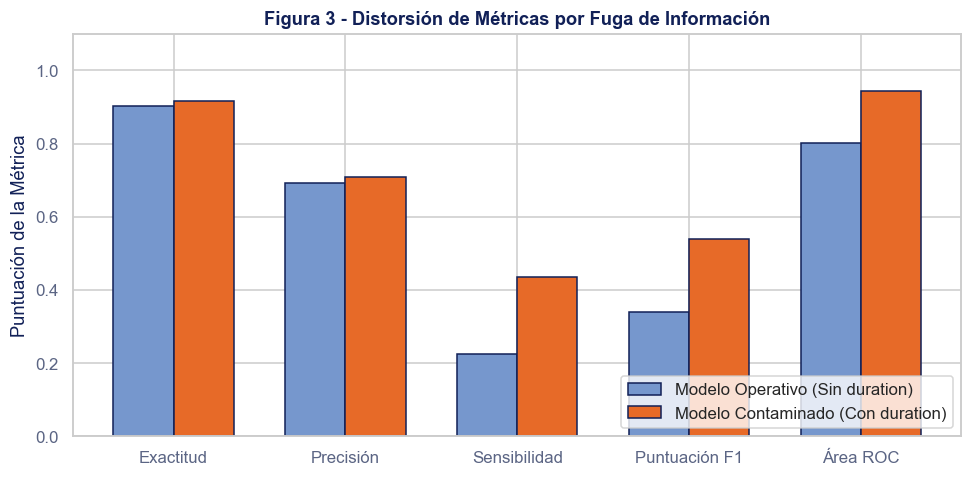

In [12]:
# Visualizacion comparativa de rendimiento
metricas_nombres = ["Exactitud", "Precisión", "Sensibilidad", "Puntuación F1", "Área ROC"]
valores_sin = [acc_05, prec_05, rec_05, f1_val_05, area_roc]
valores_con = [acc_c, prec_c, rec_c, f1_c, auc_c]

posiciones = np.arange(len(metricas_nombres))
ancho_barra = 0.35

plt.figure(figsize=(9, 4.5))
plt.bar(posiciones - ancho_barra/2, valores_sin, ancho_barra, label="Modelo Operativo (Sin duration)", color=AZUL, edgecolor=AZUL_OSCURO)
plt.bar(posiciones + ancho_barra/2, valores_con, ancho_barra, label="Modelo Contaminado (Con duration)", color=NARANJA, edgecolor=AZUL_OSCURO)

plt.xticks(posiciones, metricas_nombres)
plt.ylim(0, 1.1)
plt.ylabel("Puntuación de la Métrica")
plt.title("Figura 3 - Distorsión de Métricas por Fuga de Información")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Respuesta al Punto 6 (Efecto de la Filtración y Utilidad):**  
Al reincorporar la duración, las métricas experimentan un salto ficticio donde la sensibilidad casi se duplica ($22.41\% \to 43.43\%$) y el área bajo la curva escala a un deslumbrante $0.9425$. Dichas cifras carecen de utilidad real hacia el equipo comercial, en virtud de que un operador telefónico no puede ingresar los minutos de una conversación antes de descolgar la línea. La aparente mejora matemática es una trampa metodológica que colapsaría en la ejecución productiva del centro de contacto.

---

## 10. Síntesis Metodológica y Hallazgos del Estudio

La siguiente matriz reúne las etapas analíticas desarrolladas en la práctica:

| Etapa del Análisis | Procedimiento Metodológico | Hallazgo Central Documentado |
| :--- | :--- | :--- |
| **1. Auditoría de Variables** | Inspección de `names.txt` y exclusión preventiva de `duration`. | Se suprime una fuga de datos invalidante en la planificación comercial. |
| **2. Evaluación de Línea Base** | Partición estratificada 80/20 y ajuste de clasificador de clase mayoritaria. | Revela la falacia de la exactitud ($88.73\%$) ante el desbalance severo de clases. |
| **3. Clasificación Inicial** | Regresión logística en `Pipeline` evaluada con umbral probabilístico $0.50$. | Demuestra alta especificidad ($98.74\%$) empero baja sensibilidad ($22.41\%$). |
| **4. Diagnóstico de Curvas** | Análisis gráfico comparativo entre curva ROC ($AUC = 0.8007$) y curva PR ($AP = 0.4657$). | La curva PR delata la erosión de precisión oculta por los verdaderos negativos en ROC. |
| **5. Optimización Financiera** | Minimización de pérdidas esperadas con costo de $5$ e ingreso de $50$ por contacto. | El umbral $0.10$ maximiza el beneficio neto ($22,060$ frente a $8,900$ del umbral $0.50$). |
| **6. Simulación de Fuga** | Reincorporación de `duration` al modelo logístico de referencia. | Provoca un inflado espurio del rendimiento ($AUC = 0.9425$) inoperable en la realidad. |

---

## 11. Referencias Bibliográficas (Normas APA 7.ª Edición)

- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, *47*(4), 547–553. https://doi.org/10.1016/j.dss.2009.05.016
- Domingos, P. (2012). A few useful things to know about machine learning. *Communications of the ACM*, *55*(10), 78–87. https://doi.org/10.1145/2347736.2347755
- Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters*, *27*(8), 861–874. https://doi.org/10.1016/j.patrec.2005.10.010
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in R* (2nd ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1
- Moro, S., Cortez, P., & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, *62*, 22–31. https://doi.org/10.1016/j.dss.2014.03.001
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, *10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432
- Sokolova, M., & Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, *45*(4), 427–437. https://doi.org/10.1016/j.ipm.2009.03.002
- VanderPlas, J. (2022). *Python data science handbook: Essential tools for working with data* (2nd ed.). O'Reilly Media.

**NOTA:** Se utilizó ChatGPT como apoyo para comprender el funcionamiento de las métricas de evaluación y las herramientas de clasificación implementadas en Python. Por ejemplo, se explicó el uso de `confusion_matrix()` para analizar los aciertos y errores del modelo, así como de `roc_auc_score()` y `average_precision_score()` para evaluar su capacidad de discriminación ante un conjunto de datos desbalanceado. También se recibió orientación sobre la implementación de un flujo de procesamiento con `Pipeline`, `ColumnTransformer`, `StandardScaler` y `OneHotEncoder`, además del cálculo de un umbral de decisión basado en costos operativos y beneficios económicos. Finalmente, se utilizó la herramienta como apoyo para documentar las funciones del código y comprender los efectos de la fuga de información (*data leakage*) al incorporar la variable `duration` en el modelo predictivo.